# Parte teórica

Classifique as afirmações em Verdadeiro ou Falso, justifique as afirmativas falsas

1 - RLE é um método de compressão de complexo implementação, que consiste em indicar quantas vezes uma sequência de valores diferentes aparecem ao longo de uma imagem, sendo portanto mais eficiente em imagens com muitas cores diferentes;
Caso a imagem tenha muitos valores iguais, pode acabar deixando o resultado pior do que o original.

**Resposta:** Falso, além de o RLE ser um dos métodos de compressão de mais simples implementação, caso a imagem tenha muitos valores iguais, ou seja, cores iguais, o RLE consegue deixar o arquivo mais comprimido, o oposto também é verdade, caso a imagem tenha muitas cores diferentes, o RLE pode deixar o arquivo maior.

2 - Ao descomprimir uma imagem JPEG ela volta a ser igual a antes da compressão, isso contece devido ao processo de quantização.

**Resposta:** Falso, já que o estilo de compressão JPEG é um modelo lossy, que significa que o que foi perdido com a compressão não consegue ser recuperado.

3 - De acordo com o Teorema de Nyquist-Shannon, um sinal deve ser amostrado a uma frequência pelo menos duas vezes maior que a frequência máxima a ser reproduzida.

**Resposta:** Verdadeiro.

4 - Sinais de áudio são, por natureza, analógicos.

**Resposta:** Verdadeiro.

5 - No contexto de áudios, frequência de amostragem é a frequência com que são captadas amostras do audio digital para gerar um analógico.

**Resposta:** Falso, a lógica é a inversa, frequência de amostragem é a frequência com que são captadas amostras do áudio analógico para gerar um digital.

# Parte prática

## Material de apoio

## Material de apoio

### Importações

```python
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
```

### Manipulação de imagens

```python
img = Image.open('nome.extensão')
img = np.array(Image.open('nome.extensão'))
img = img[:, :, :3]
img_pil = Image.fromarray(img_np)
img.save('nome.png')
Image.fromarray(img).save('nome_arquivo.extensao')
(l,c,p) = img.shape
```

### Greyscale

#### Algoritmo genérico, substituir o método escolhido
```python
img_avg = np.zeros(shape=(l, c), dtype=np.uint8)
for i in range(l):
    for j in range(c):
        r = float(img_np[i, j, 0])
        g = float(img_np[i, j, 1])
        b = float(img_np[i, j, 2])
        
        img_avg[i, j] = (aplicar método)
```

#### Métodos:


Lightness: $\frac{max(R,G,B)+min(R,G,B)}{2}$


Average: $\frac{R+G+B}{3}$


Luminosity: $0.2126 \cdot R + 0.7152 \cdot G + 0.0722 \cdot B$


RGB para CMY:
### <font color="red">R</font><font color="green">G</font><font color="blue">B</font> para <font color="cyan">C</font><font color="magenta">M</font><font color="yellow">Y</font>
$$\begin{pmatrix}
    C \\ M \\ Y
\end{pmatrix} = \begin{pmatrix}
    1 \\ 1 \\ 1
\end{pmatrix} - \begin{pmatrix}
    R \\ G \\ B
\end{pmatrix} e \begin{pmatrix}
    R \\ G \\ B
\end{pmatrix} = \begin{pmatrix}
    1 \\ 1 \\ 1
\end{pmatrix} - \begin{pmatrix}
    C \\ M \\ Y
\end{pmatrix}$$
* **<font color="red">R</font>** + **<font color="cyan">C</font>** = 1 (ou 255);
* **<font color="green">G</font>** + **<font color="magenta">M</font>** = 1;
* **<font color="blue">B</font>** + **<font color="yellow">Y</font>** = 1.


Interpolação Bilinear:
Seja $I$ a imagem de entrada $L_{entrada}×C_{entrada}$ e $J$ a imagem de saída $L_{saída}×C_{saída}.$

Seja $s_L = L_{entrada}/L_{saída}$ e $s_C = C_{entrada}/C_{saída}.$

Seja $l_f = l \cdot s_L$ para $r=0,\ldots,R_{saída}-1$ e $c_f = c \cdot s_C$ para $c=0,\ldots,C_{saída}-1.$

Seja $r_0 = \lfloor{l_f}\rfloor$ e $c=\lfloor{c_f}\rfloor.$

Seja $\Delta_l = l_f - l_0$ e $\Delta_c = c_f - c_0.$

Então $J(l, c)$
$$=I(l_0, c_0) \cdot (1-\Delta_l) \cdot (1-\Delta_c)$$
$$+I(l_0+1, c_0) \cdot \Delta_l \cdot (1-\Delta_c)$$
$$+I(l_0, c_0+1) \cdot (1-\Delta_l) \cdot \Delta_c$$
$$+I(l_0+1, c_0+1) \cdot \Delta_l \cdot \Delta_c.$$

### Escalonamento com nearest neighbor

```python
ls, cs = l * sy, c * sx
mario_nn = np.zeros(shape=(ls, cs, p), dtype=np.uint8)

for i in range(ls):
    for j in range(cs):
        new_y = int(np.floor(i * (l / ls)))
        new_x = int(np.floor(j * (c / cs)))
        
        mario_nn[i, j] = mario[new_y, new_x]
```
### Escalonamento clássico
```python
scale_x, scale_y = 2, 2
mario_scale = np.zeros(shape=(l * scale_y, c * scale_x, p), dtype=np.uint8)
for i in range(l):
    for j in range(c):
        new_x = np.round(j * scale_x)
        new_y = np.round(i * scale_y)
        mario_scale[new_y, new_x] = mario[i, j]

plt.imshow(mario_scale)
Image.fromarray(mario_scale).save('mario_scale.png')
```

### Cisalhamento

```python
img_shear = np.zeros((int(l * (1.1 + cy)), int(c * (1.1 + cx)), p), dtype=np.uint8)
for i in range(l):
    for j in range(c):
        new_x = int(j + cx * i)
        new_y = int(cy * j + i)
        
        img_shear[new_y, new_x] = img[i, j]
```

### Imagem grayscale para imagem binária de 3 canais

```python
bin = np.zeros(shape=(l,c,3),dtype=np.uint8)
    
for i in range(l):
    for j in range(c):
        if img[i,j] > thresh:
            bin[i,j,:] = 255
        else:
            bin[i,j,:] = 0

```
### Blending com escala genérica

```python
imagem_blending = (C * img_1) + ((1 - C) * img_2)
imagem_blending = imagem_blending.astype(np.uint8)
```

### Histograma
```python
def histogram_gray(img):
    (l, c) = img.shape
    histogram = np.zeros(256, dtype=np.int32)

    for i in range(l):
        for j in range(c):
            intensity = img[i, j]
            histogram[intensity] += 1
            
    return histogram

def show_histogram_gray(img):
    histogram = histogram_gray(img)
    plt.figure(figsize=(16, 16))
    plt.subplot(2, 1, 1)
    plt.imshow(img, cmap='gray', vmin=0, vmax=255)
    plt.subplot(2, 1, 2)
    plt.bar(range(256), histogram)

def show_histogram(img):
    histogram_r = histogram_gray(img[:, :, 0])
    histogram_g = histogram_gray(img[:, :, 1])
    histogram_b = histogram_gray(img[:, :, 2])
    
    plt.figure(figsize=(16, 16))
    plt.subplot(2, 1, 1)
    plt.imshow(img, cmap='gray', vmin=0, vmax=255)
    plt.subplot(2, 1, 2)
    plt.bar(range(256), histogram_r, color='red')
    plt.bar(range(256), histogram_g, color='green')
    plt.bar(range(256), histogram_b, color='blue')

```
### Espelhamento
```python
refl = np.zeros(shape=example.shape, dtype=np.uint8)
for i in range(l):
    for j in range(c):
        new_x = -j
        new_y = i
        refl[new_y, new_x] = example[i, j]

plt.imshow(refl)
```


No outro eixo

```python
refl = np.zeros(shape=example.shape, dtype=np.uint8)
refl[::-1, ::1] = example
plt.imshow(refl)
```

### Detecção de bordas
```python
abs_tg_c = np.abs(np.diff(museum.astype(np.float64), axis=0, append=255))

abs_tg_l = np.abs(np.diff(museum.astype(np.float64), axis=1, append=255))

abs_tg = np.sqrt(abs_tg_c ** 2 + abs_tg_l ** 2)

threshold = 16
museum_border = np.zeros(shape=(l, c), dtype=np.uint8)
museum_border[abs_tg > threshold] = 255
```

### Operações lógicas
NOT:
```python
bin1_not = np.bitwise_not(bin1)
bin2_not = np.invert(bin2)
```
AND:
```python
bin_and = np.bitwise_and(bin1, bin2)
```
OR:
```python
bin_or = np.bitwise_or(bin1, bin2)
```
XOR
```python
bin_xor = np.bitwise_xor(bin1, bin2)
```
### Compressão

#### RLE
```
def rle_encode(data):
    encoding = []
    
    if not data:
        return encoding
    
    prev = data[0]
    count = 0
    
    for value in data:
        if value != prev:
            encoding.append(count)
            encoding.append(prev)
            count = 1
            prev = value
        else:
            count += 1
            
    encoding.append(count)
    encoding.append(prev)
    
    return encoding
```

#### Huffman
```
hist_sorted_indexes = np.argsort(hist)[::-1]
hist_sorted = hist[hist_sorted_indexes]
indexes = hist_sorted_indexes[hist_sorted > 0]
probs = hist[indexes] / img.size
probabilities = np.zeros(shape=(indexes.size, 2))
probabilities[:, 0] = indexes
probabilities[:, 1] = probs
```

#### Quantização de frequência
```
import numpy as np

values = np.array([13, 10, 9, 141, -4, 2, 260, 289, 120, -498])
delta = 10
quantized = delta * np.floor(values / delta + 0.5)
print(quantized)
```
### Áudios
```
from scipy.io import wavfile
import sounddevice as sd
import matplotlib.pyplot as plt
import numpy as np

fs, data = wavfile.read("DITTY1.WAV")
sd.play(data, fs)
sd.stop()
print("Canais:", data.shape)
print("Número de amostras:", data.shape[0])
print("Profundidade de bits:", data.dtype)
print("Taxa de Amostragem:", fs)
print("Taxa de bits:", 8 * fs * 1)

fs = 10000
f = 440
t = 2
audio = np.zeros(shape = (fs * t, 1), dtype = np.float32)
for i in range(fs * t):
    audio[i, 0] = np.sin(2 * np.pi * f * i / fs)
sd.play(audio, fs)

fs, data = wavfile.read("Roundabout.wav")
sd.play(data[fs * 40:, :], fs)
sd.stop()
parte = data[fs * 40:fs * 45, :].astype(np.float32) / 32767
sd.play(0.1 * parte, fs)

plt.figure(figsize = (16,16))
plt.subplot(2, 1, 1)
plt.plot(data[:, 0])
plt.subplot(2, 1, 2)
plt.plot(data[:, 1])

wavfile.write("audio.wav", fs, parte)
```
### Processamento de áudios

```
from scipy import signal
import numpy as np
import sounddevice as sd
import matplotlib.pyplot as plt
from scipy.io import wavfile

def threshold(data, thresh):
    data_abs = np.abs(data)
    data_thresh = np.where(data_abs >= thresh, data, 0)
    return data_thresh

def denoise(data, fs, thresh):
    nperseg=120
    win = signal.hamming(nperseg)
    noverlap = 80
    
    fftlen = 512
    _, _, Zxx = signal.stft(data, fs, window=win, noverlap=noverlap, nfft=fftlen, nperseg=nperseg)
    z_thresh = threshold(Zxx, thresh)
    
    _, x = signal.istft(z_thresh, fs, window=win, noverlap=noverlap, nfft=fftlen, nperseg=nperseg)
    return x

np.random.seed(0)

def add_noise(data, noise_level):
    noise = np.random.normal(size=data.shape) * noise_level
    return data + noise
```
### Vídeo
```
import moviepy.editor as mpe
import numpy as np

video = mpe.VideoFileClip("bigbuckbunny.mp4")
video.ipython_display(width=480)

print('Tamanho:', video.size)
print('FPS:', video.fps)
print('Duração:', video.duration, 'segundos')
print('Número de frames:', video.reader.nframes)

print(video.get_frame(5).dtype)

l, c, p = video.get_frame(0).shape
print('Taxa de dados:', (p * 8) * l * c * video.fps, 'bps')

sum_frames = np.zeros(shape=(video.h, video.w, 3), dtype=np.float32) # float32 para evitar overflow
num_frames = video.reader.nframes

for frame in video.iter_frames():
    sum_frames = sum_frames + frame

avg_frames = (sum_frames / num_frames).astype(np.uint8)

plt.imshow(avg_frames)

def invert(frame):
    return (255-frame)

video_inverted = video.fl_image(invert)

part_1 = video.subclip(0, 3)
part_2 = video.subclip(3, 4).fl_image(invert)
part_3 = video.subclip(4) # 4 segundos até o fim

parts = mpe.concatenate_videoclips([part_1, part_2, part_3])
parts.write_videofile('video_parts.mp4')
parts.ipython_display(width=480)

def increase(audio, t):
    frame = audio(t)
    frame[:, 0] *= t / video.duration
    frame[:, 1] *= t / video.duration
    
    return frame

audio_increase = video.audio.fl(increase)
video_audio_increase = video.set_audio(audio_increase)
```



**1 -** Importe as bibliotecas que serão usadas

In [20]:
import moviepy.editor as mp
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio
from scipy.io.wavfile import write
from scipy.io import wavfile

##### **2 -** Abra o vídeo "bigbuckbunny.mp4 " e salve-o em uma variável, pegue o **frame do segundo 5**, aplique inversão de cores e exiba.

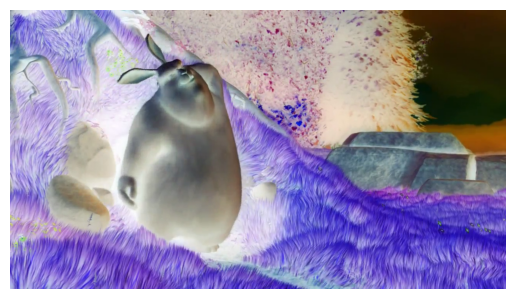

In [ ]:
# Carregar o vídeo
video = mp.VideoFileClip("bigbuckbunny.mp4")

frame_segundo_5 = video.get_frame(5)
cor_invertida = 255 - frame_segundo_5
plt.imshow(cor_invertida)
plt.axis('off')
plt.show()

**3 -** Crie uma função que receba um frame e retorne um frame aplicado detecção de bordas do frame selecionado com treshold de 3, aplique essa função no vídeo e observe o resultado. **Sua função deve retornar um frame com 3 páginas para evitar problemas**.

In [ ]:
def aplicacao_bordas(frame):
  abs_tg_c = np.abs(np.diff(frame.astype(np.float64), axis=0, append=255))
  abs_tg_l = np.abs(np.diff(frame.astype(np.float64), axis=1, append=255))
  abs_tg = np.sqrt(abs_tg_c ** 2 + abs_tg_l ** 2)
  abs_tg_gray = np.mean(abs_tg, axis=2)

  l, c, _ = frame.shape
  thresh = 3
  bin_border = np.zeros(shape=(l, c, 3), dtype=np.uint8)

  bin_border[abs_tg_gray > thresh] = 255

  return bin_border

In [ ]:
video_bordas = video.fl_image(aplicacao_bordas)
video_bordas.ipython_display(width=480)

Moviepy - Building video __temp__.mp4.
MoviePy - Writing audio in __temp__TEMP_MPY_wvf_snd.mp3


MoviePy - Done.
Moviepy - Writing video __temp__.mp4



t: 100%|██████████| 133/133 [00:18<00:00,  6.28it/s, now=None]WARNING:py.warnings:/usr/local/lib/python3.12/dist-packages/moviepy/video/io/ffmpeg_reader.py:123: UserWarning: Warning: in file bigbuckbunny.mp4, 2764800 bytes wanted but 0 bytes read,at frame 132/133, at time 5.28/5.31 sec. Using the last valid frame instead.
  warnings.warn("Warning: in file %s, "%(self.filename)+



Moviepy - Done !
Moviepy - video ready __temp__.mp4


**4 -** Crie uma função que receba um frame e retorne um frame convertido em escala de cinza, aplique essa função no vídeo e observe o resultado. **Sua função deve retornar um frame com 3 páginas para evitar problemas**.

In [ ]:
def escala_cinza(frame):
  r = frame[:,:,0]
  g = frame[:,:,1]
  b = frame[:,:,2]
  luminosity = 0.2126 * r + 0.7152 * g + 0.0722 * b

  l, c, _ = frame.shape
  frame_cinza_3d = np.zeros(shape=(l, c, 3), dtype=np.uint8)

  frame_cinza_3d[:, :, 0] = luminosity
  frame_cinza_3d[:, :, 1] = luminosity
  frame_cinza_3d[:, :, 2] = luminosity

  return frame_cinza_3d

In [ ]:
video_cinza = video.fl_image(escala_cinza)

video_cinza.ipython_display(width=480)

Moviepy - Building video __temp__.mp4.
MoviePy - Writing audio in __temp__TEMP_MPY_wvf_snd.mp3


MoviePy - Done.
Moviepy - Writing video __temp__.mp4



t:  98%|█████████▊| 130/133 [00:05<00:00, 28.67it/s, now=None]WARNING:py.warnings:/usr/local/lib/python3.12/dist-packages/moviepy/video/io/ffmpeg_reader.py:123: UserWarning: Warning: in file bigbuckbunny.mp4, 2764800 bytes wanted but 0 bytes read,at frame 132/133, at time 5.28/5.31 sec. Using the last valid frame instead.
  warnings.warn("Warning: in file %s, "%(self.filename)+

                                                              

Moviepy - Done !
Moviepy - video ready __temp__.mp4


**5 -** Separe o vídeo original em 2 subclips:
- Segundos 0 ao 2: Aplicar detecção de bordas
- Segundos 2 em diante: Aplique escala de cinza

**Una esses clips em um único vídeo e exiba o resultado.**

In [ ]:
subclip_0_2 = video.subclip(0, 2)
subclip_2_fim = video.subclip(2)

subclip_0_2_deteccao = subclip_0_2.fl_image(aplicacao_bordas)
subclip_2_fim_cinza = subclip_2_fim.fl_image(escala_cinza)

video_final = mp.concatenate_videoclips([subclip_0_2_deteccao, subclip_2_fim_cinza])
video_final.ipython_display(width=480)


Moviepy - Building video __temp__.mp4.
MoviePy - Writing audio in __temp__TEMP_MPY_wvf_snd.mp3


MoviePy - Done.
Moviepy - Writing video __temp__.mp4



t:  99%|█████████▉| 132/133 [00:08<00:00, 41.03it/s, now=None]WARNING:py.warnings:/usr/local/lib/python3.12/dist-packages/moviepy/video/io/ffmpeg_reader.py:123: UserWarning: Warning: in file bigbuckbunny.mp4, 2764800 bytes wanted but 0 bytes read,at frame 132/133, at time 5.28/5.31 sec. Using the last valid frame instead.
  warnings.warn("Warning: in file %s, "%(self.filename)+



Moviepy - Done !
Moviepy - video ready __temp__.mp4


**6 -** Gere um arquivo de áudio contendo uma senoide de 500Hz com duração de 3 segundos, em seguida toque-a. Após isso, manipule o áudio de modo que ele fique mais grave, após toque-o.

In [21]:
fs = 44100
f = 500
t = 3

audio = np.zeros(shape=(fs * t, 1), dtype=np.float32)
for i in range(fs * t):
  audio[i, 0] = np.sin(2 * np.pi * f * i / fs)

Audio(data=audio.flatten(), rate=fs)

In [23]:
f_grave = 250
audio_grave = np.zeros(shape=(fs * t, 1), dtype=np.float32)
for i in range(fs * t):
    audio_grave[i, 0] = np.sin(2 * np.pi * f_grave * i / fs)

Audio(data=audio_grave.flatten(), rate=fs)

**7 -** Gere os gráficos referente aos dois aúdios da questão anterior.

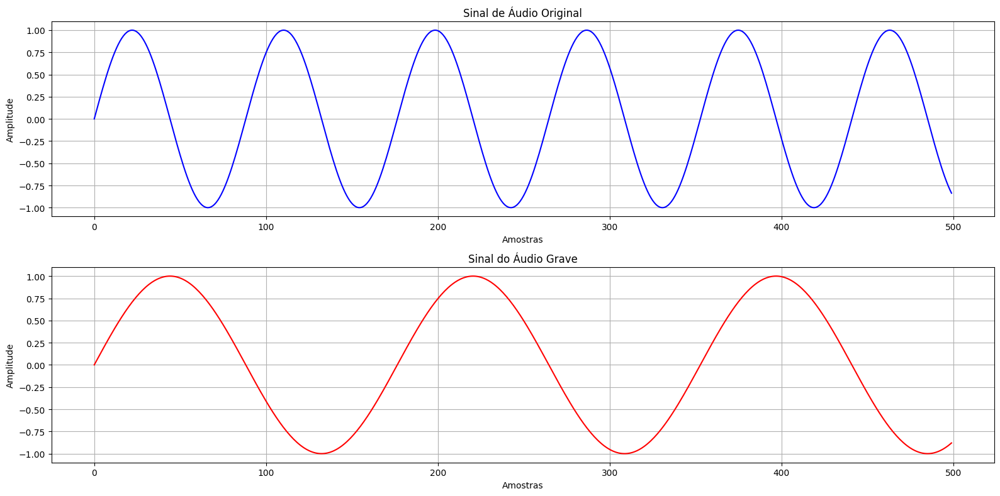

In [25]:
trecho_visualizacao = 500

plt.figure(figsize=(16, 8))

plt.subplot(2, 1, 1)
plt.plot(audio[:trecho_visualizacao, 0], color='blue')
plt.title("Sinal de Áudio Original")
plt.xlabel("Amostras")
plt.ylabel("Amplitude")
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(audio_grave[:trecho_visualizacao, 0], color='red')
plt.title("Sinal do Áudio Grave")
plt.xlabel("Amostras")
plt.ylabel("Amplitude")
plt.grid(True)

plt.tight_layout()
plt.show()

**8 -** Salve o vídeo resultante da questão 5 como "resultado_video.mp4" e o áudio resultante da questão 6 como "resultado_audio_grave

In [27]:
video_final.write_videofile('resultado_video.mp4')
wavfile.write("resultado_audio_grave.wav", fs, audio_grave)

Moviepy - Building video resultado_video.mp4.
MoviePy - Writing audio in resultado_videoTEMP_MPY_wvf_snd.mp3


MoviePy - Done.
Moviepy - Writing video resultado_video.mp4



t: 100%|██████████| 133/133 [00:20<00:00,  7.58it/s, now=None]WARNING:py.warnings:/usr/local/lib/python3.12/dist-packages/moviepy/video/io/ffmpeg_reader.py:123: UserWarning: Warning: in file bigbuckbunny.mp4, 2764800 bytes wanted but 0 bytes read,at frame 132/133, at time 5.28/5.31 sec. Using the last valid frame instead.
  warnings.warn("Warning: in file %s, "%(self.filename)+



Moviepy - Done !
Moviepy - video ready resultado_video.mp4


# Lembre de entregar tudo como um arquivo ZIP, com o arquivo resultado e seu notebook, NOMEADO COMO: "C09 - LX - SEU NOME COMPLETO"